# Exploratory Data Analysis: free tiers of AI video-generation models

**Dataset:** *AI video model free-tier data* (videofreetier.com, CC BY 4.0) - dated observations of what twelve AI video products grant, charge and refuse to state on their free tiers.
Fields: `model, channel, metric, value, observed, source_type, note`.

**Method:** follows the NIST/SEMATECH *Exploratory Data Analysis* handbook: look at each variable on its own (histogram / bar chart, summary statistics, outliers), then at variables together (box plots, scatter matrix, cross-tabs).

### A note on the structure of this dataset
The raw table is almost entirely *text* (`value` holds strings such as `"125 one-time credits"`). To satisfy the assignment criteria (>= 30 rows, >= 8 attributes, >= 5 numerical), I **engineer** attributes from the text. These are clearly labelled below, and their limits are discussed in the conclusions:

| engineered attribute | type | how it is built |
|---|---|---|
| `value_num` | numeric | first number found in `value` (dates, `HTTP 200` removed; thousands separators handled) |
| `n_numbers` | numeric | how many numbers appear in `value` |
| `value_len` | numeric | characters in `value` |
| `metric_words` | numeric | words in `metric` |
| `observed_ord` | numeric | days since the earliest observation date |
| `metric_category` | categorical | grant / cost / limit / watermark / access / api / absence / other (keyword rules) |
| `channel_type` | categorical | official / logged-in / anonymous / third-party (from the channel string) |
| `is_absence` | categorical (bool) | the value records a documented absence ("not published", ...) |

If `data/seedance-2-5-free-tiers.csv` (the full 117-row file, which also has the `model` and `note` columns) is present, the notebook uses it. Otherwise it falls back to `data/preview_rows.psv`, which I transcribed from the dataset's preview table (no `model` column; `model` is inferred from the channel).

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)

FULL = Path("data/seedance-2-5-free-tiers.csv")
PREVIEW = Path("data/preview_rows.psv")
if FULL.exists():
    df = pd.read_csv(FULL); SOURCE = "full CSV"
else:
    df = pd.read_csv(PREVIEW, sep="|"); SOURCE = "preview rows (transcribed)"
print("source:", SOURCE, "| shape:", df.shape)
df.head()

source: preview rows (transcribed) | shape: (117, 5)


,channel,metric,value,observed,source_type
0,Jimeng,daily free credits,60-100,2026-07-04,report
1,Jimeng,daily free credits,88,2026-08-11,report
2,Doubao,daily generations (free tier),5,2026-08-11,report
3,Mina Labs,sign-up bonus,20 credits,2026-08-11,report
4,Lovart,annual plan bonus,up to 20 generations,2026-08-11,report


## 1. Feature engineering

In [2]:
def infer_model(ch):
    c = ch.lower()
    rules = [("pixverse","PixVerse"), ("runway","Runway"), ("wan.video","Wan 2.5"),
             ("kling","Kling AI"), ("openai","Sora 2"), ("grok","Grok Imagine"), ("x.ai","Grok Imagine"),
             ("invideo","Invideo AI"), ("hailuo","Hailuo AI"), ("luma","Luma Dream Machine"),
             ("canva","Canva"), ("google","Veo 3.1")]
    for key, name in rules:
        if key in c: return name
    return "Seedance 2.5"          # Jimeng, Doubao, ByteDance, BytePlus, hosts, API reports

def channel_type(ch):
    c = ch.lower()
    if "anonymous" in c or "unauthenticated" in c: return "anonymous"
    if "logged-in" in c or "free account" in c or "free google account" in c: return "logged-in"
    if any(k in c for k in ["official", "pricing", "docs.", "help."]): return "official"
    return "third-party"

ABSENCE = re.compile(r"not published|not stated|not listed|not reachable|not measurable|no amount|^none|not available|no figure", re.I)
def metric_category(row):
    m, v = row["metric"].lower(), str(row["value"]).lower()
    if ABSENCE.search(v): return "absence"
    if "without logging in" in m: return "access"
    if "watermark" in m: return "watermark"
    if any(k in m for k in ["credit consumption", "credit cost", "credit deduction", "api price", "what one ai video"]): return "cost"
    if any(k in m for k in ["resolution", "duration", "length", "storage", "ceiling", "concurrent", "output limits", "image styles", "stock library"]): return "limit"
    if any(k in m for k in ["api availab", "error", "billing", "availability"]): return "api"
    if any(k in m for k in ["credits", "allowance", "daily", "bonus", "giveaway", "per month", "trial", "plan", "videos per month", "generations"]): return "grant"
    return "other"

NUM = re.compile(r"\d[\d,]*\.?\d*")
def clean_for_numbers(s):
    s = re.sub(r"\d{4}-\d{2}(-\d{2})?", " ", str(s))      # dates
    s = re.sub(r"HTTP \d+", " ", s)                           # status codes
    return s
def numbers(s):
    out = []
    for t in NUM.findall(clean_for_numbers(s)):
        try: out.append(float(t.replace(",", "")))
        except ValueError: pass
    return out

if "model" not in df.columns:
    df["model"] = df["channel"].map(infer_model)
df["channel_type"] = df["channel"].map(channel_type)
df["is_absence"] = df["value"].astype(str).str.contains(ABSENCE)
df["metric_category"] = df.apply(metric_category, axis=1)

nums = df["value"].map(numbers)
df["value_num"] = nums.map(lambda l: l[0] if l else np.nan)
df["n_numbers"] = nums.map(len)
df["value_len"] = df["value"].astype(str).str.len()
df["metric_words"] = df["metric"].astype(str).str.split().str.len()
dt = pd.to_datetime(df["observed"], errors="coerce")          # ranges like '2026-07 to 2026-08' -> NaT
df["observed_ord"] = (dt - dt.min()).dt.days

NUMERIC = ["value_num", "n_numbers", "value_len", "metric_words", "observed_ord"]
CATEG = ["model", "channel_type", "metric_category", "source_type", "is_absence"]
print(f"{len(df)} rows | {len(NUMERIC)} numeric + {len(CATEG)} categorical engineered/native attributes")
print("unparseable dates:", int(dt.isna().sum()), "| rows with no number in value:", int(df['value_num'].isna().sum()))
df[["model","channel_type","metric_category","source_type","is_absence"] + NUMERIC].head(12)

117 rows | 5 numeric + 5 categorical engineered/native attributes
unparseable dates: 2 | rows with no number in value: 49


,model,channel_type,metric_category,source_type,is_absence,value_num,n_numbers,value_len,metric_words,observed_ord
0,Seedance 2.5,third-party,grant,report,False,60.0,2,6,3,0.0
1,Seedance 2.5,third-party,grant,report,False,88.0,1,2,3,38.0
2,Seedance 2.5,third-party,grant,report,False,5.0,1,1,4,38.0
3,Seedance 2.5,third-party,grant,report,False,20.0,1,10,2,38.0
4,Seedance 2.5,third-party,grant,report,False,20.0,1,20,3,38.0
5,Seedance 2.5,third-party,grant,report,False,30.0,2,41,2,52.0
6,Seedance 2.5,official,limit,vendor,False,30.0,1,23,3,27.0
7,Seedance 2.5,official,limit,vendor,False,NaN,0,35,2,27.0
8,Seedance 2.5,third-party,limit,report,False,3.0,1,22,2,4.0
9,Seedance 2.5,official,absence,vendor,True,NaN,0,10,2,27.0


## 2. One variable at a time (NIST: univariate views)
### 2.1 Numerical variables - histograms and summary statistics

In [3]:
def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return s[(s < q1 - 1.5*i) | (s > q3 + 1.5*i)]

rows = []
for c in NUMERIC:
    s = df[c].dropna()
    o = iqr_outliers(df[c])
    rows.append(dict(variable=c, n=len(s), min=s.min(), max=s.max(), mean=s.mean(), median=s.median(),
                     std=s.std(), Q1=s.quantile(.25), Q3=s.quantile(.75), n_outliers=len(o)))
stats = pd.DataFrame(rows).set_index("variable").round(2)
stats

,n,min,max,mean,median,std,Q1,Q3,n_outliers
variable,,,,,,,,,
value_num,68,0.0,99000.0,1688.27,20.0,12038.59,5.0,60.0,10
n_numbers,117,0.0,23.0,1.21,1.0,2.43,0.0,1.0,14
value_len,117,1.0,274.0,42.96,36.0,38.85,13.0,56.0,4
metric_words,117,2.0,8.0,3.97,4.0,1.47,3.0,5.0,0
observed_ord,115,0.0,96.0,81.83,92.0,24.06,90.0,93.0,20


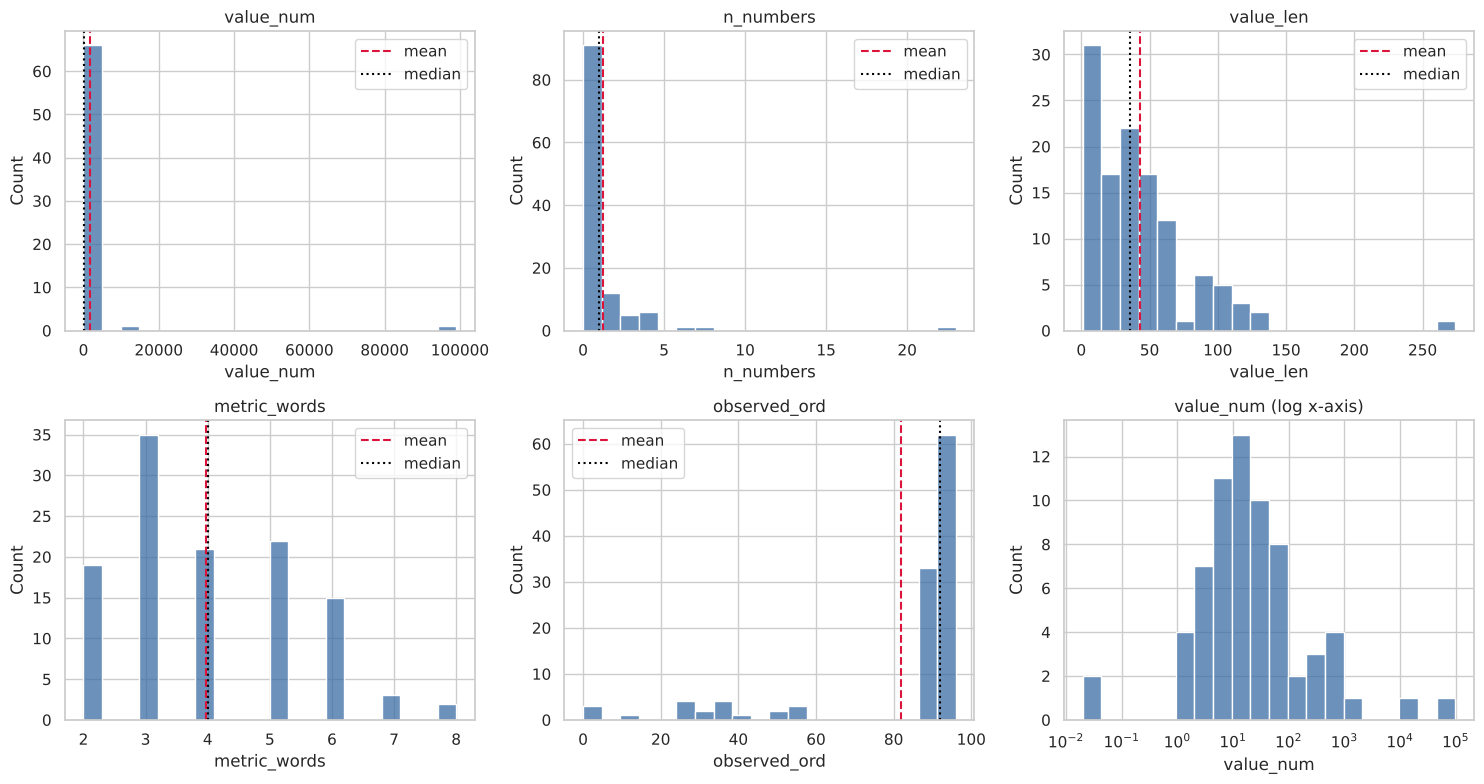

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8)); axes = axes.ravel()
for ax, c in zip(axes, NUMERIC):
    sns.histplot(df[c].dropna(), bins=20, ax=ax, color="#3b6ea5")
    ax.axvline(df[c].mean(), color="crimson", ls="--", label="mean")
    ax.axvline(df[c].median(), color="black", ls=":", label="median")
    ax.set_title(c); ax.legend()
sns.histplot(df["value_num"].dropna(), bins=20, log_scale=True, ax=axes[5], color="#3b6ea5")
axes[5].set_title("value_num (log x-axis)")
plt.tight_layout(); plt.show()

In [5]:
for c in NUMERIC:
    s, o = df[c].dropna(), iqr_outliers(df[c])
    ol = ", ".join(f"{v:g}" for v in sorted(o.unique())[:8]) or "none"
    print(f"{c:13s} min={s.min():g}  max={s.max():g}  mean={s.mean():.2f}  median={s.median():g}  "
          f"-> {len(o)} outlier(s) by the 1.5*IQR rule: {ol}")

value_num     min=0  max=99000  mean=1688.27  median=20  -> 10 outlier(s) by the 1.5*IQR rule: 300, 400, 429, 529, 540, 660, 1080, 10000
n_numbers     min=0  max=23  mean=1.21  median=1  -> 14 outlier(s) by the 1.5*IQR rule: 3, 4, 6, 8, 23
value_len     min=1  max=274  mean=42.96  median=36  -> 4 outlier(s) by the 1.5*IQR rule: 121, 132, 136, 274
metric_words  min=2  max=8  mean=3.97  median=4  -> 0 outlier(s) by the 1.5*IQR rule: none
observed_ord  min=0  max=96  mean=81.83  median=92  -> 20 outlier(s) by the 1.5*IQR rule: 0, 4, 11, 27, 31, 38, 39, 52


### 2.2 Categorical variables - bar charts

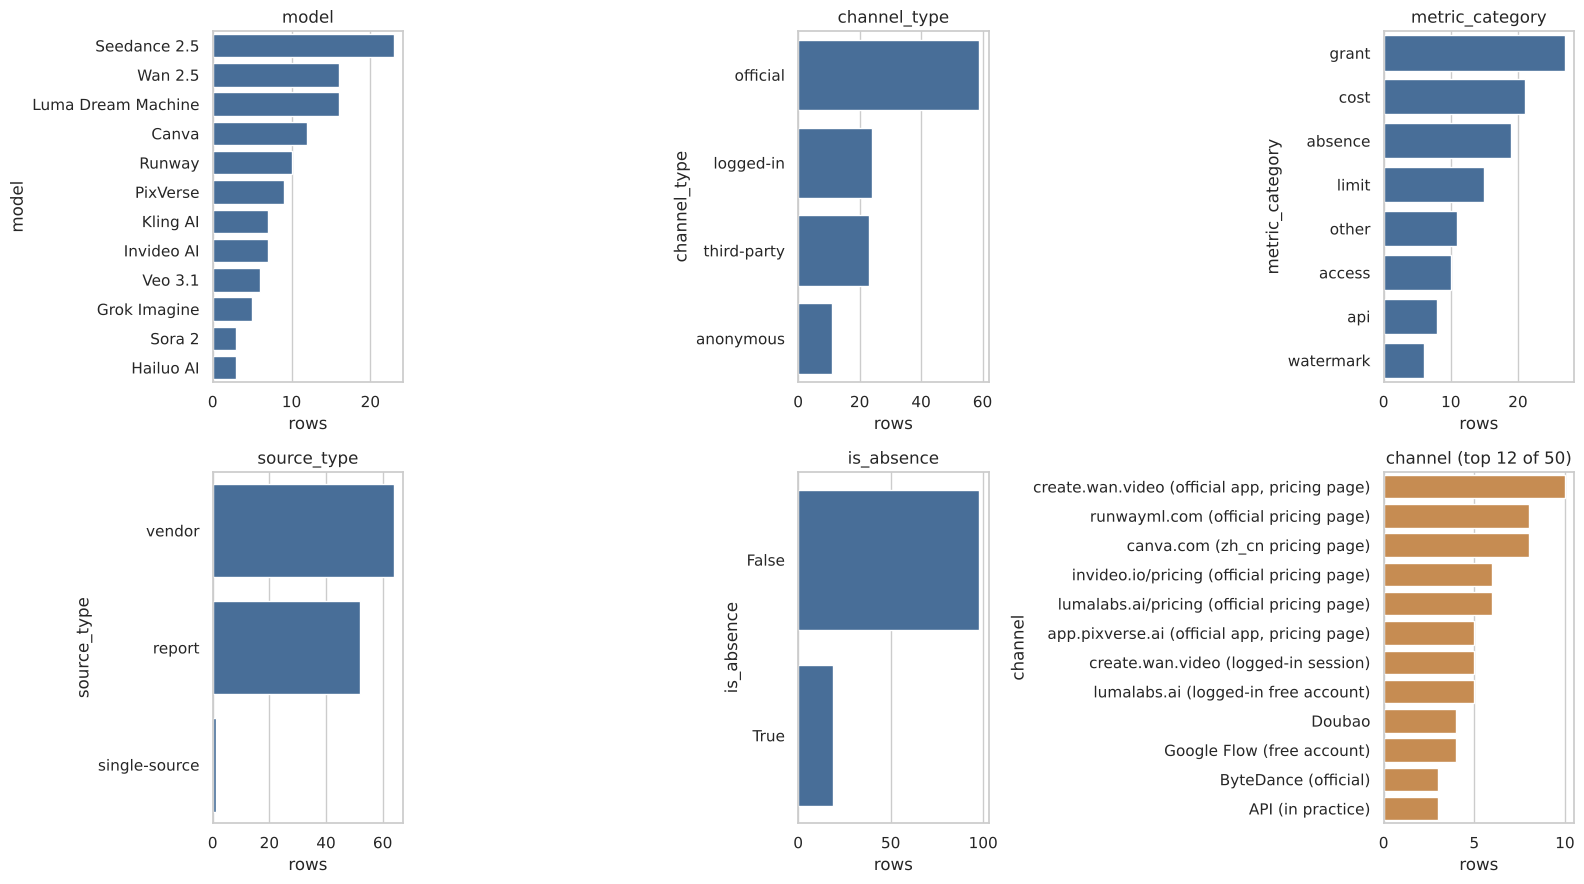

model: 12 levels; most common = Seedance 2.5 (23 rows, 20%); least common = Hailuo AI (3)
channel_type: 4 levels; most common = official (59 rows, 50%); least common = anonymous (11)
metric_category: 8 levels; most common = grant (27 rows, 23%); least common = watermark (6)
source_type: 3 levels; most common = vendor (64 rows, 55%); least common = single-source (1)
is_absence: 2 levels; most common = False (98 rows, 84%); least common = True (19)


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9)); axes = axes.ravel()
for ax, c in zip(axes, CATEG):
    vc = df[c].value_counts()
    sns.barplot(x=vc.values, y=vc.index.astype(str), ax=ax, color="#3b6ea5")
    ax.set_title(c); ax.set_xlabel("rows")
top = df["channel"].value_counts().head(12)
sns.barplot(x=top.values, y=top.index, ax=axes[5], color="#d98c3f")
axes[5].set_title("channel (top 12 of %d)" % df["channel"].nunique()); axes[5].set_xlabel("rows")
plt.tight_layout(); plt.show()

for c in CATEG:
    vc = df[c].value_counts()
    print(f"{c}: {len(vc)} levels; most common = {vc.index[0]} ({vc.iloc[0]} rows, {vc.iloc[0]/len(df):.0%}); least common = {vc.index[-1]} ({vc.iloc[-1]})")

### 2.3 All numerical variables side by side - one box plot
The variables live on very different scales (a count of numbers vs. days vs. credits), so a raw box plot would flatten all but one. Each variable is therefore **z-scored** (mean 0, std 1) so that the boxes are comparable; dots beyond the whiskers are the 1.5*IQR outliers.

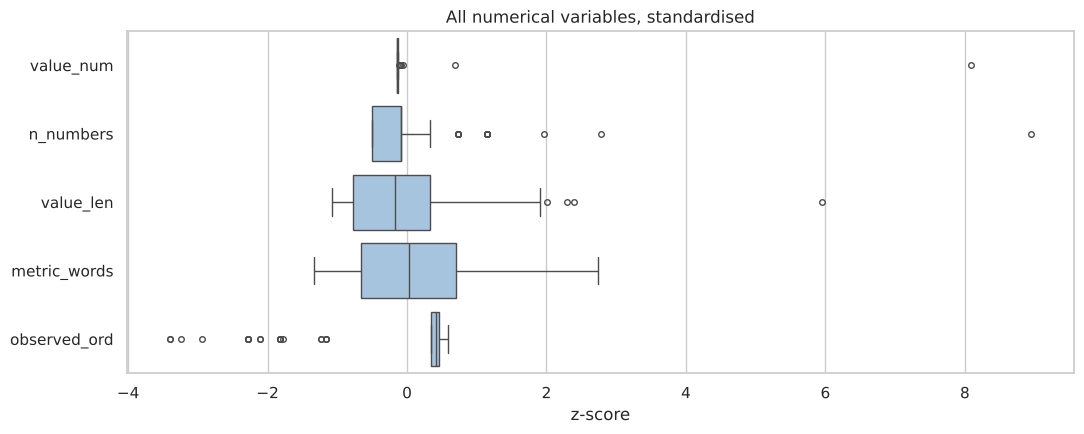

In [7]:
z = (df[NUMERIC] - df[NUMERIC].mean()) / df[NUMERIC].std()
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=z, orient="h", ax=ax, color="#9ec5e8", fliersize=4)
ax.set_xlabel("z-score"); ax.set_title("All numerical variables, standardised")
plt.tight_layout(); plt.show()

## 3. Pair-wise relationships
### 3.1 Numerical vs numerical - scatter-plot matrix

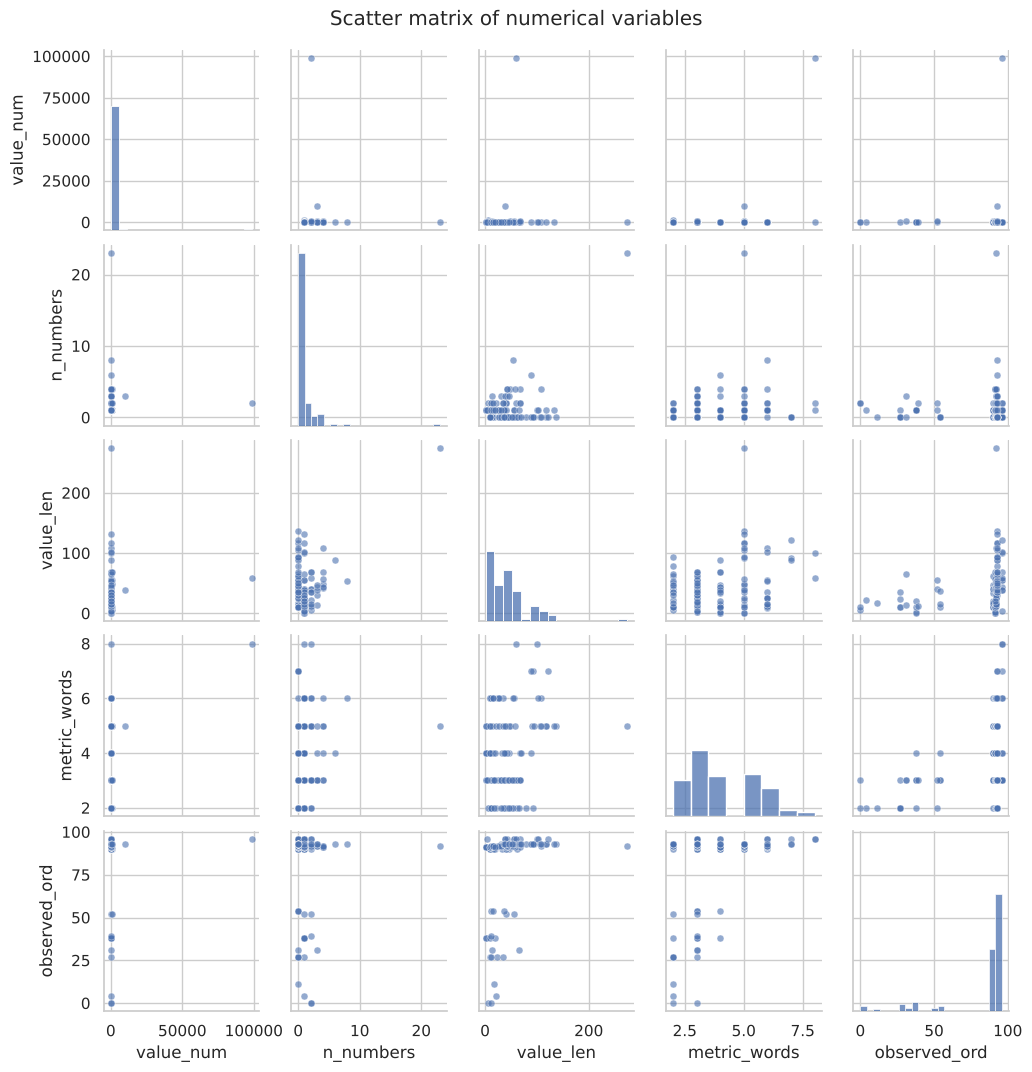

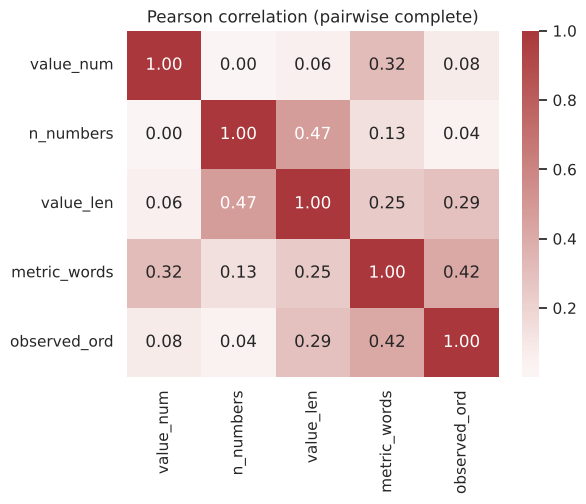

In [8]:
g = sns.pairplot(df[NUMERIC], diag_kind="hist", corner=False, plot_kws=dict(alpha=.6, s=25), height=2.1)
g.figure.suptitle("Scatter matrix of numerical variables", y=1.02); plt.show()

plt.figure(figsize=(6, 4.5))
sns.heatmap(df[NUMERIC].corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Pearson correlation (pairwise complete)"); plt.show()

### 3.2 Categorical vs categorical - aggregate one variable against another
Count the rows in every pair of categories (a cross-tab), shown as a heat map, then aggregate: the share of rows that are documented absences, by model.

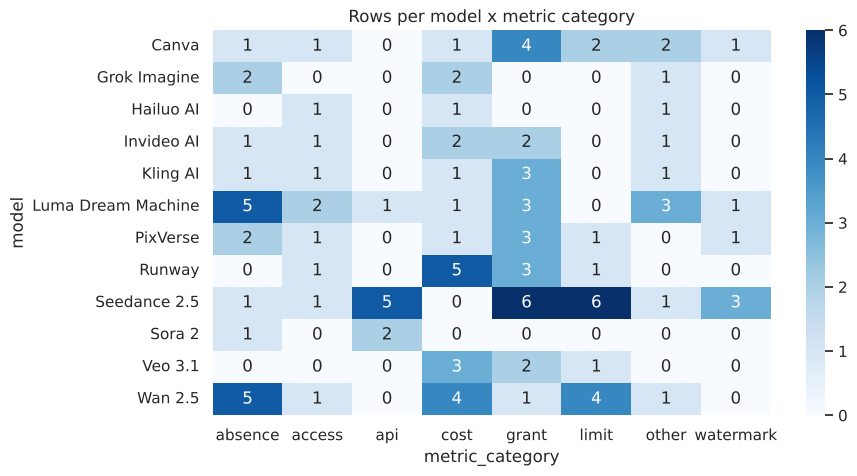

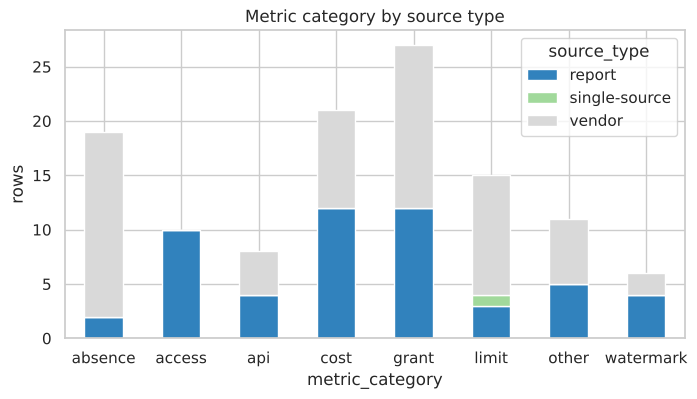

,share_absence,absences,rows
model,,,
Grok Imagine,0.40,2,5
Sora 2,0.33,1,3
Luma Dream Machine,0.31,5,16
Wan 2.5,0.31,5,16
PixVerse,0.22,2,9
Kling AI,0.14,1,7
Invideo AI,0.14,1,7
Canva,0.08,1,12
Seedance 2.5,0.04,1,23


In [9]:
ct = pd.crosstab(df["model"], df["metric_category"])
plt.figure(figsize=(9, 5)); sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title("Rows per model x metric category"); plt.show()

ct2 = pd.crosstab(df["metric_category"], df["source_type"])
ct2.plot(kind="bar", stacked=True, figsize=(8, 4), colormap="tab20c")
plt.title("Metric category by source type"); plt.ylabel("rows"); plt.xticks(rotation=0); plt.show()

absence_share = df.groupby("model")["is_absence"].agg(["mean", "sum", "count"]).sort_values("mean", ascending=False)
absence_share["mean"] = absence_share["mean"].round(2)
absence_share.rename(columns={"mean": "share_absence", "sum": "absences", "count": "rows"})

### 3.3 Categorical vs numerical - colour and grouping
Group boxes by category, and colour scatter points by category.

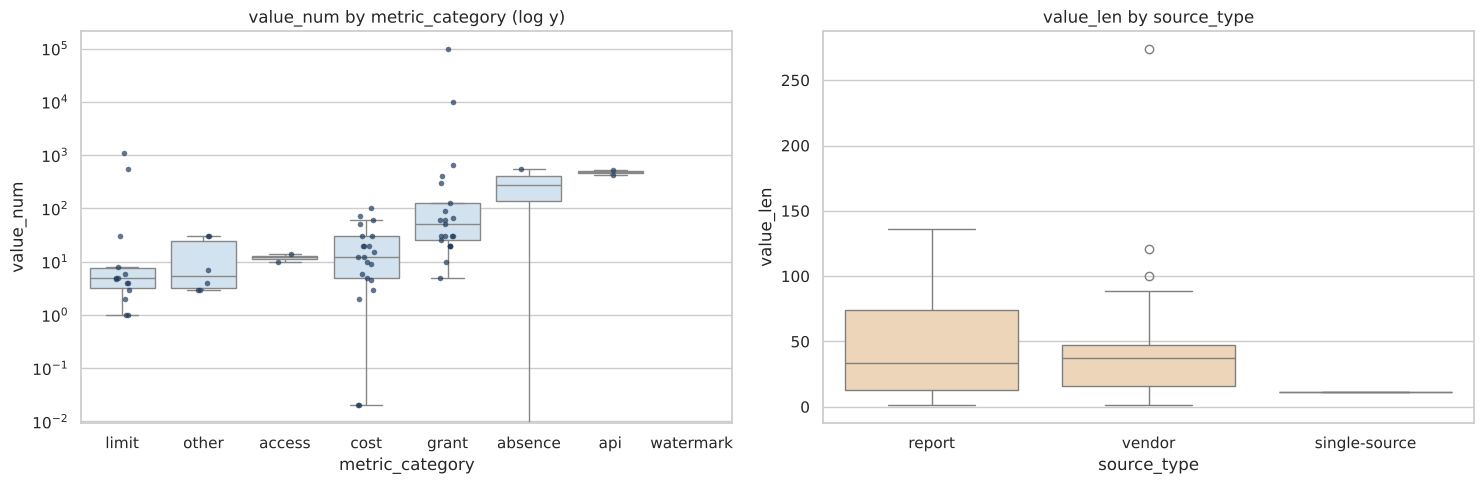

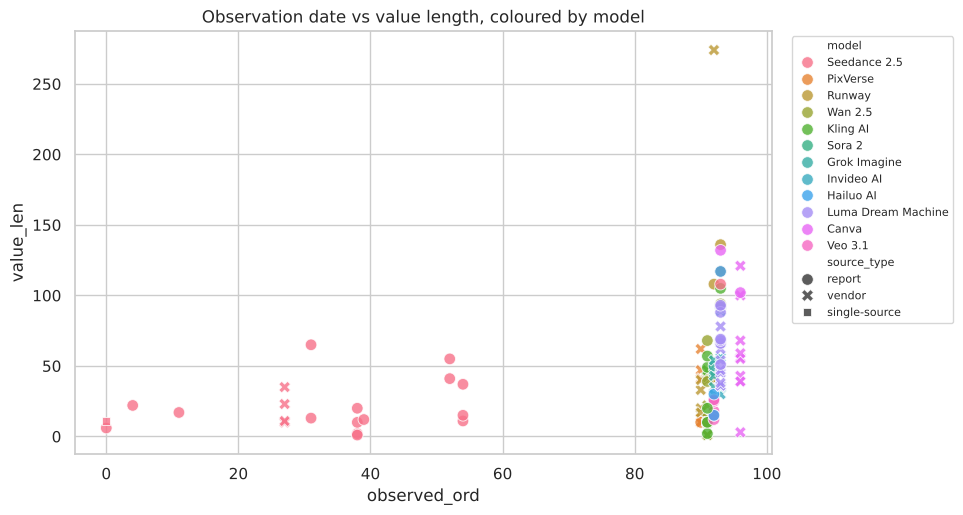

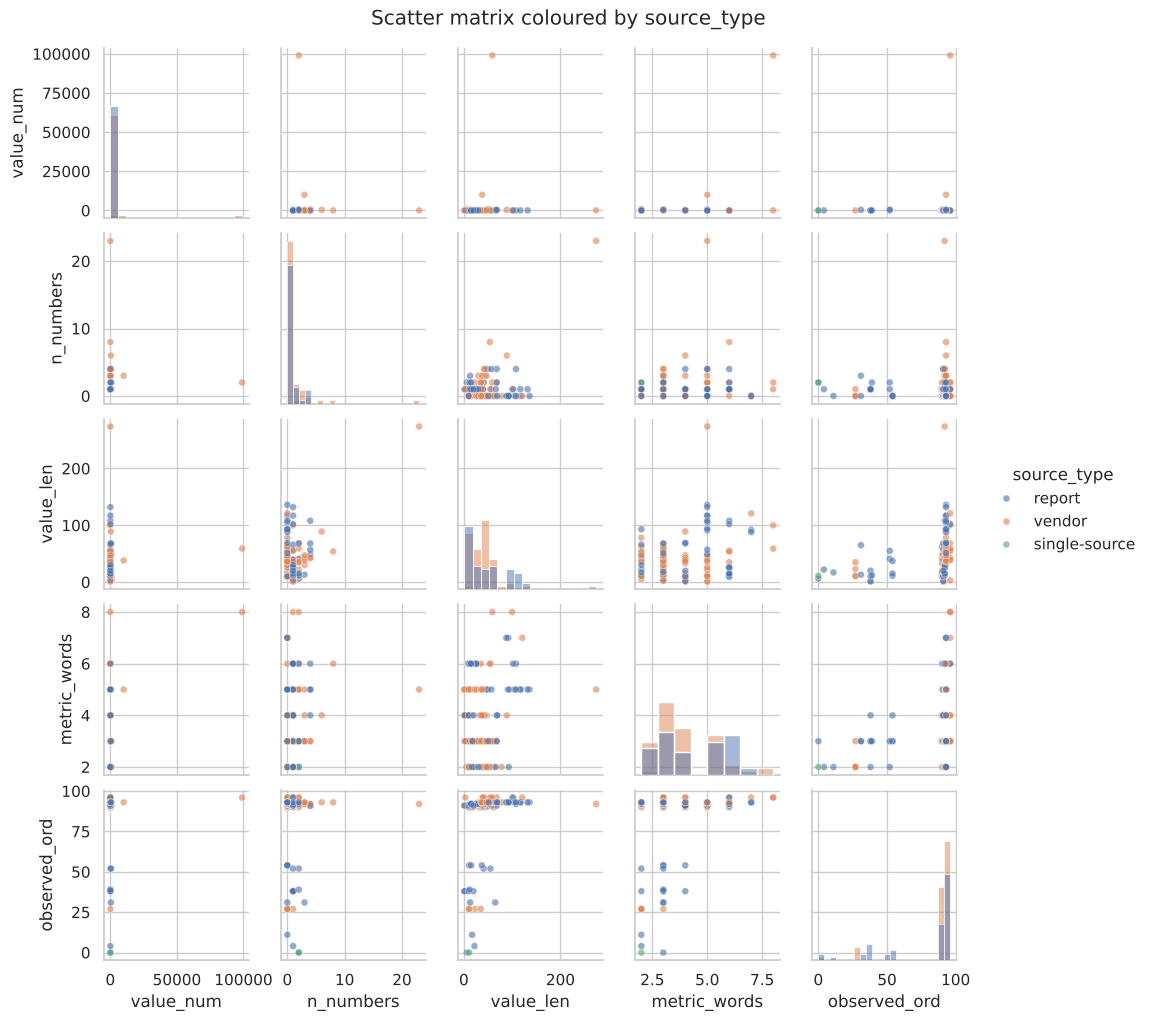

value_num        n_numbers        value_len        metric_words        observed_ord       
                     mean median      mean median      mean median         mean median         mean median
metric_category                                                                                           
absence             270.0  270.0       0.2    0.0      35.5   41.0          3.4    3.0         88.6   92.0
access               12.0   12.0       0.2    0.0     108.0  106.5          5.4    5.0         93.0   93.0
api                 479.0  479.0       0.5    0.0      34.4   26.0          3.0    3.0         53.6   41.5
cost                 22.9   12.0       2.9    1.0      47.8   35.0          4.8    6.0         91.9   92.0
grant              5287.1   50.0       1.5    1.0      30.9   30.0          3.8    4.0         79.4   91.0
limit               121.0    4.8       1.3    1.0      18.0   11.0          3.5    3.0         68.2   91.0
other                12.8    5.5       1.2    1.0      58.2   50.0          4.0    3.0         88.1   93.0
watermark             NaN    NaN       0.0    0.0      41.5   46.0          3.7    3.5         73.5   72.0

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
order = df.groupby("metric_category")["value_num"].median().sort_values().index
sns.boxplot(data=df, x="metric_category", y="value_num", order=order, ax=axes[0], color="#cfe2f3", fliersize=0)
sns.stripplot(data=df, x="metric_category", y="value_num", order=order, ax=axes[0], color="#1f3b5c", size=4, alpha=.7)
axes[0].set_yscale("log"); axes[0].set_title("value_num by metric_category (log y)")
sns.boxplot(data=df, x="source_type", y="value_len", ax=axes[1], color="#f6d6b0")
axes[1].set_title("value_len by source_type")
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=df, x="observed_ord", y="value_len", hue="model", style="source_type", s=70, alpha=.8)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.title("Observation date vs value length, coloured by model"); plt.show()

g = sns.pairplot(df[NUMERIC + ["source_type"]], hue="source_type", diag_kind="hist", height=2, plot_kws=dict(alpha=.6, s=25))
g.figure.suptitle("Scatter matrix coloured by source_type", y=1.02); plt.show()

df.groupby("metric_category")[NUMERIC].agg(["mean", "median"]).round(1)

## 4. Conclusions

**Numerical variables (117 rows; 5 numeric attributes).**
- `value_num` (68 rows have a number): min 0, max 99,000, mean about 1,688, median 20. The mean is nearly 100x the median because of 10 outliers by the 1.5*IQR rule, the largest being a Canva price in Korean won (99,000) and a 10,000-credit Luma plan. This is the clearest case in the data for preferring the **median**. Caveat: `value_num` mixes units (credits, seconds, dollars, pixels), so it describes the *shape* of the numbers on these pages, not a comparable quantity.
- `n_numbers`: median 1, max 23 (Runway's per-model cost table); 14 outliers.
- `value_len`: min 1, median 36, mean 43, max 274 characters (again the Runway cost table); 4 outliers. Rows describing what an anonymous visitor sees are the wordiest.
- `metric_words`: 2 to 8 words, median 4, no outliers.
- `observed_ord`: 0 to 96 days, median 92. 115 of 117 dates parse (two are ranges). The 20 "outliers" are the early (July-August) Seedance observations; almost everything else was recorded in the first week of October. The dataset is therefore a **snapshot**, not a time series.

**Categorical variables.** 12 models (Seedance 2.5 largest with 23 rows, 20%); half of all rows come from official pages (59) and 55% are `vendor`-sourced (64), with a single `single-source` row. 19 rows (16%) are documented absences under my keyword rule. This is broader than the 14 the dataset's own text counts, so treat my flag as an approximation.

**Relationships.**
- The scatter matrix shows no strong linear relationship between any pair of numeric variables: the heavy-tailed `value_num` and the date clustering swamp everything else. `n_numbers` and `value_len` rise together a little, which is expected (more numbers means longer text), and is driven by the Runway cost table.
- Categorical vs categorical: the share of rows that are absences is highest for Grok Imagine (40%, 5 rows), Sora 2 (33%, 3 rows), Luma Dream Machine and Wan 2.5 (31% each); Runway, Veo 3.1 and Hailuo AI have none. Small per-model counts make these shares fragile.
- Categorical vs numerical: `cost` rows have a median `value_num` of 12 (credits per second or per generation) versus 50 for `grant` rows, whose mean (about 5,300) is inflated by outliers. Colouring by `source_type` shows vendor and report rows overlapping almost completely on every numeric pair.

**Limits of this analysis.** The source is mostly text, so every numeric attribute is derived and noisy; 49 rows have no number at all. Several categories have very few rows (3 for Sora 2 and Hailuo AI). If the full CSV is dropped into `data/`, the notebook uses its real `model` column instead of the inferred one.